#   Automatically generating limits
There are a few tests that might be hard to get started with but are very important to understand for effective use of QARTOD:
* The `gross_range_test`
* And `climatology_test`

These tests require operational thresholds in order to operate them properly. However, what do you do if you don't know what these limits are?

Welcome to the `auto_limits` module, which will identify what your limits could be via reproducible statistical methods.

This notebook will run through an example of using the `auto_limits` module to automatically generate some limits for setting up these tests on a dataset that perhaps you or the operator aren't too familiar with.

**TL;DR: Skip to the end of this notebook for a summary of recommendations on getting started with unknown bounds.**

##  Setup
Start by downloading some example data. In this case, some water level data from North Carolina. This has more than a year of data, which will be great for constructing a seasonal climatology for.

In [1]:
import pandas as pd
import pooch

# Belhaven, NC water level from SECOORA ERDDAP (CSV; row 2 holds units).
# pooch caches the file in the OS cache dir (e.g. ~/.cache/ioos_qc), not in the repo.
url = (
    "https://erddap.secoora.org/erddap/tabledap/belhaven-nc.csv"
    "?time%2Cwater_surface_above_navd88%2Cwater_surface_above_navd88_qc_agg%2Cz"
    "&time%3E%3D2024-03-06T20%3A18%3A15Z&time%3C%3D2026-11-17T20%3A24%3A00Z"
)
known_hash="sha256:9ec8f78ae59a611da71d1fe4ed62446f1442daf628777f63507d7018a995a1c9"
fname = pooch.retrieve(
    url,
    known_hash=known_hash,  # ERDDAP regenerates the CSV, so its hash can change if the data are re-QC'd
    fname="belhaven-nc.csv",
    path=pooch.os_cache("ioos_qc"),
)
df = pd.read_csv(fname, skiprows=[1], parse_dates=["time"])

Next we'll clarify which data we want to work with - `water_level` is a good example. We'll also instance a filtered version of our data for some seasonal detection down the line (see the `AutoLimits_Spike` notebook for an unfiltered example).

In [ ]:
water_level = df["water_surface_above_navd88"].to_numpy()        # meters, NAVD88
time = df["time"].dt.tz_convert("UTC").dt.tz_localize(None)      # pandas Series, tz-naive UTC
existing_qc = df["water_surface_above_navd88_qc_agg"].to_numpy() # aggregate QARTOD flags (1/3/4)

from scipy.ndimage import median_filter as md
water_level2 = md(water_level, size=3)

##  The gross range
The **gross range test** applies to the entire dataset timeframe. It has two sets of limits to pass in: `fail_span` and `suspect_span`.
* `fail_span` should come from the sensor manufacturer. This represents what the sensor is physically calibrated for or capable of measuring. If you have a temperature sensor, then it is unlikely going to be reading temperatures below -50 °C or above 100 °C, for example.
* `suspect_span` is optional and typically defined by what values are typical for the region. For example, it's rare to see temperatures below 8 °C or above 32 °C in the surface of the Gulf of Mexico.

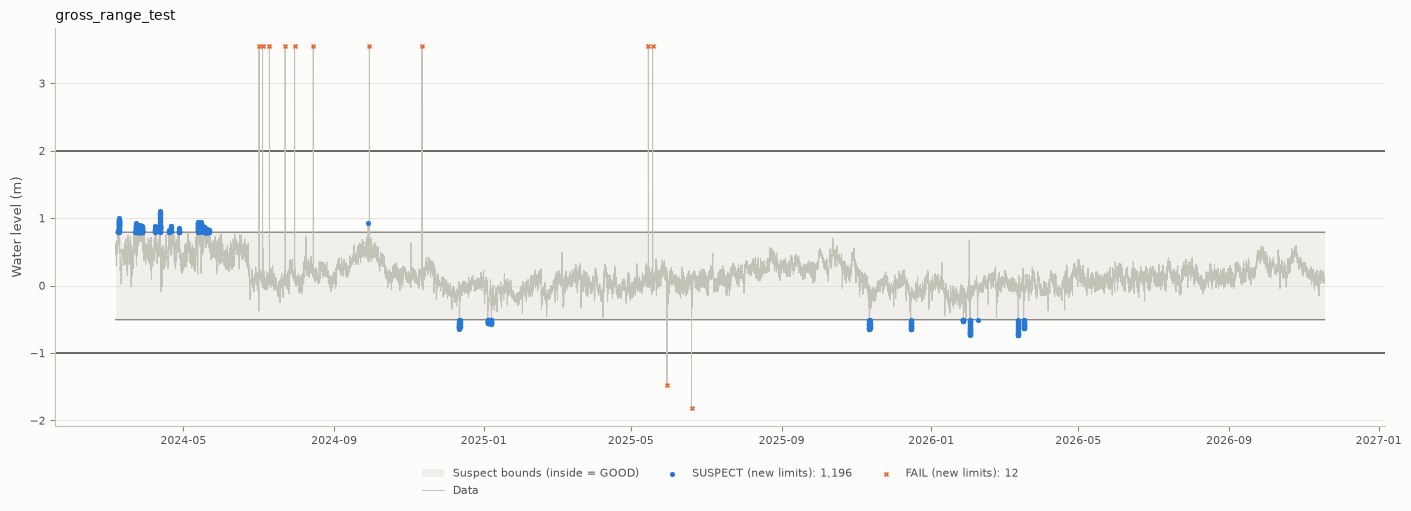

In [3]:
from ioos_qc import qartod
from ioos_qc.auto_limits import auto_climatology, auto_thresh, find_regimes
from ioos_qc.plotting import plot_limits
from ioos_qc.utils import compare_flags

# Gross range: suspect from the data, fail from the manufacturer/experts
# For this example, let's assume the sensor is capable of -1 to 2 m ranges.
suspect = auto_thresh(water_level, n_std=3)
fail = (-1.0, 2.0)
flags = qartod.gross_range_test(water_level, fail_span=fail, suspect_span=suspect)

fig = plot_limits(
    water_level,
    time,
    limits = suspect,                   # gross range: the (lower, upper) suspect span
    fail_span=fail,     # same expert fail span as the test above
    # reference=existing_qc,     # optional: adds the confusion matrix + F1 panel
    ylabel="Water level (m)",
)


##  Climatology
The **climatology** is more representative of typical values that are seen during subsets of the year or over specific timeframes. For example, what are the typical ranges for the springtime? Or is there a storm in the data that arises midway into your glider dataset that you want different QC metrics on? These are possible with the climatology using a config input, which is a series of `gross_range_test`s strung together.
* *Note: Things like storms and sensor service should be flagged as suspect in order to bring attention to the operator.* A climatology test doesn't have to fit 100% of the time. 

12 config dictionaries:
 [{'tspan': (1, 1), 'period': 'month', 'vspan': (-0.5998399865663055, 0.3692714391522203)}, {'tspan': (2, 2), 'period': 'month', 'vspan': (-0.5396464128588888, 0.48938550869975683)}, {'tspan': (3, 3), 'period': 'month', 'vspan': (-0.9215218276837475, 1.276449511392127)}, {'tspan': (4, 4), 'period': 'month', 'vspan': (-0.888006470748394, 1.1377906817127132)}, {'tspan': (5, 5), 'period': 'month', 'vspan': (-0.7889670376004921, 1.2523374555747497)}, {'tspan': (6, 6), 'period': 'month', 'vspan': (-0.630080345765957, 0.9688001578414989)}, {'tspan': (7, 7), 'period': 'month', 'vspan': (-0.33294395139384747, 0.544120284772159)}, {'tspan': (8, 8), 'period': 'month', 'vspan': (-0.32202200438463036, 0.6919223010963768)}, {'tspan': (9, 9), 'period': 'month', 'vspan': (-0.24731102989133752, 0.8283866034935032)}, {'tspan': (10, 10), 'period': 'month', 'vspan': (-0.24654311539582502, 0.8489453495594936)}, {'tspan': (11, 11), 'period': 'month', 'vspan': (-0.4665756503302969, 0

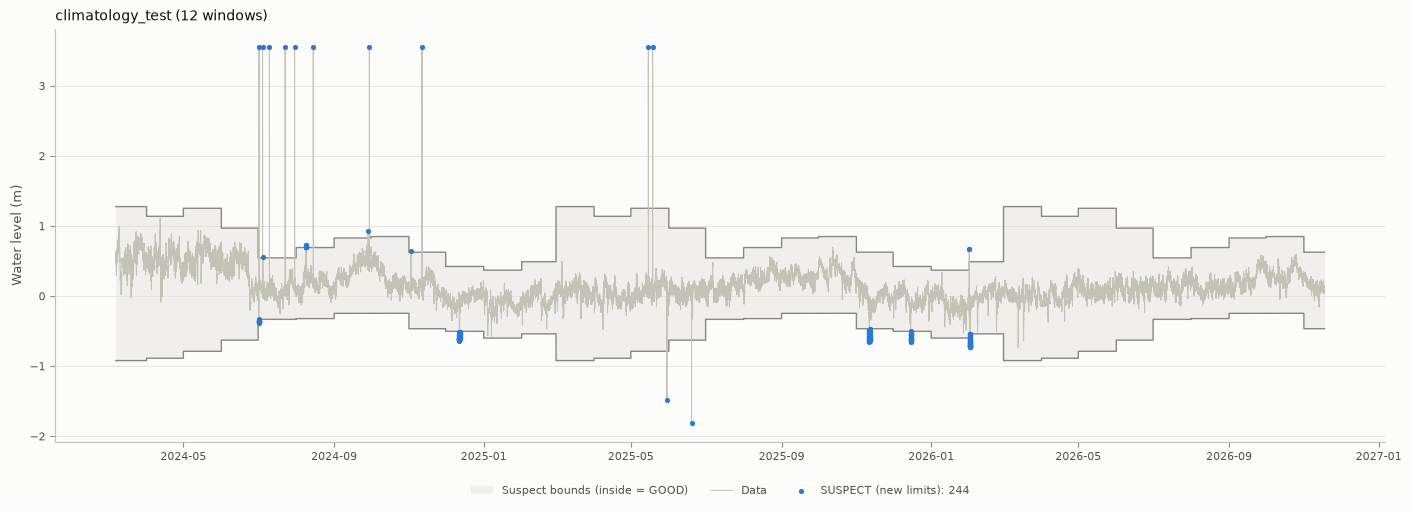

In [4]:
# What regimes are in the record?
find_regimes(water_level2, time, method="seasonal", period="month")

# Climatology config from those regimes
cfg = auto_climatology(water_level2, time, n_std=4)

flags = qartod.climatology_test(cfg, water_level, time)

# Compare with existing QC and plot
compare_flags(existing_qc, flags)["f1"]
fig = plot_limits(water_level, time, cfg, ylabel="Water level (m)") #   Add kwarg "reference=existing_qc," here for a comparison to existing flags
print(f"{len(cfg)} config dictionaries:\n {cfg}")

The example above built a 12-month climatology with `n_regimes=12`, so each calendar month gets its own suspect bounds.

Below, the same data subset is grouped into **4 regimes** with each available `method`.

* **Seasonal, by week of year** (`method="seasonal", period="weekofyear"`):
    * weeks with similar water levels are grouped, pooled across years. Windows repeat every year, so the config can be reused on future data. Weeks give finer window edges than months.
* **Segments** (`method="segments"`):
    * the record is cut into 4 contiguous date ranges, each one unbroken stretch of time (e.g. "late spring", "summer", "a storm period"). This gives exactly 4 windows, but they apply only to the dates in this record.
* **Regimes** (`method="regimes"`):
    * days are grouped by similarity alone, with no requirement that they be next to each other. A regime can recur, e.g. calm days scattered between storms all share one set of bounds. When conditions switch back and forth this produces many short windows (52 here), which shows why the time constraint in `segments` and `seasonal` is usually helpful.

In short: a **segment** is *one stretch of time*; a **regime** is *one type of conditions*, which can occur many times.

seasonal (month): 6 windows
seasonal (weekofyear): 9 windows
segments: 4 windows
regimes: 52 windows


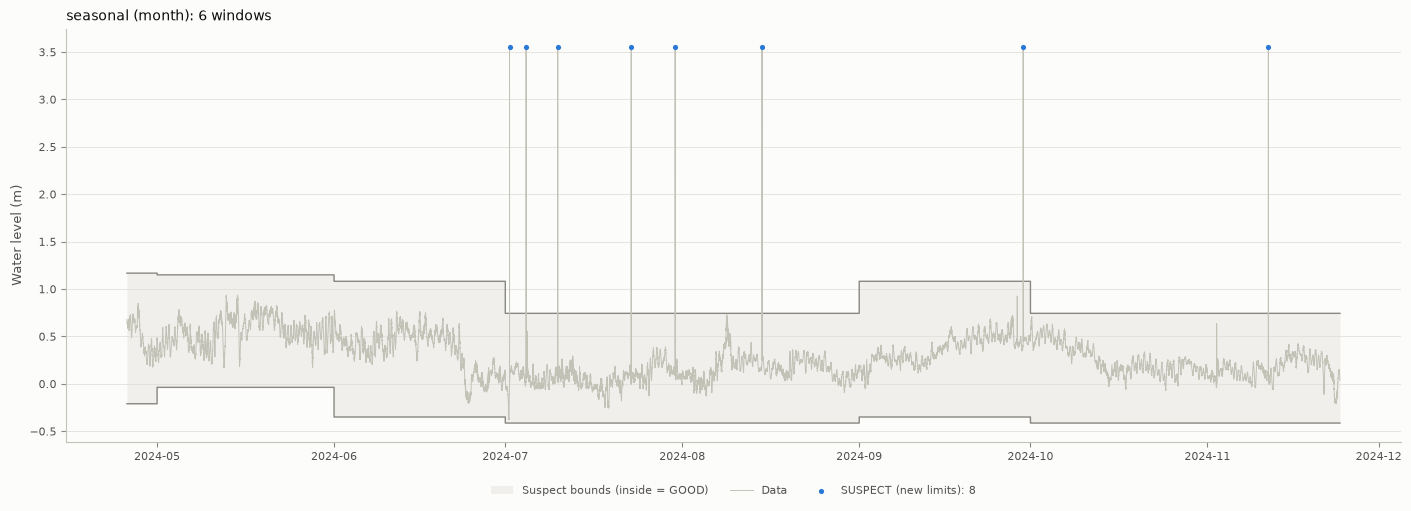

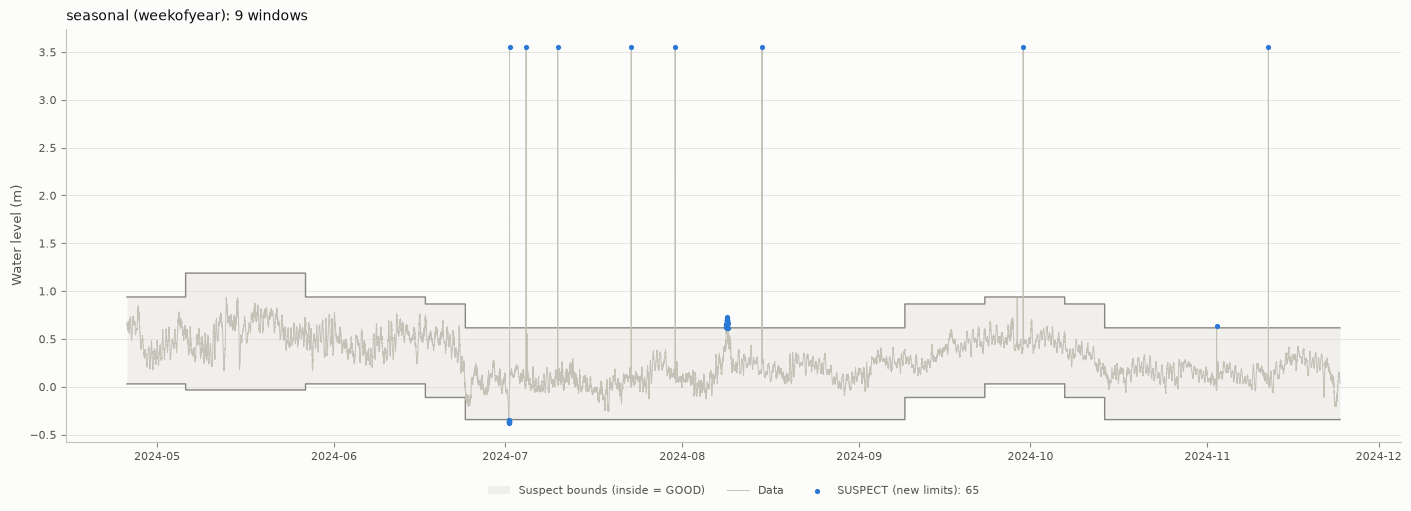

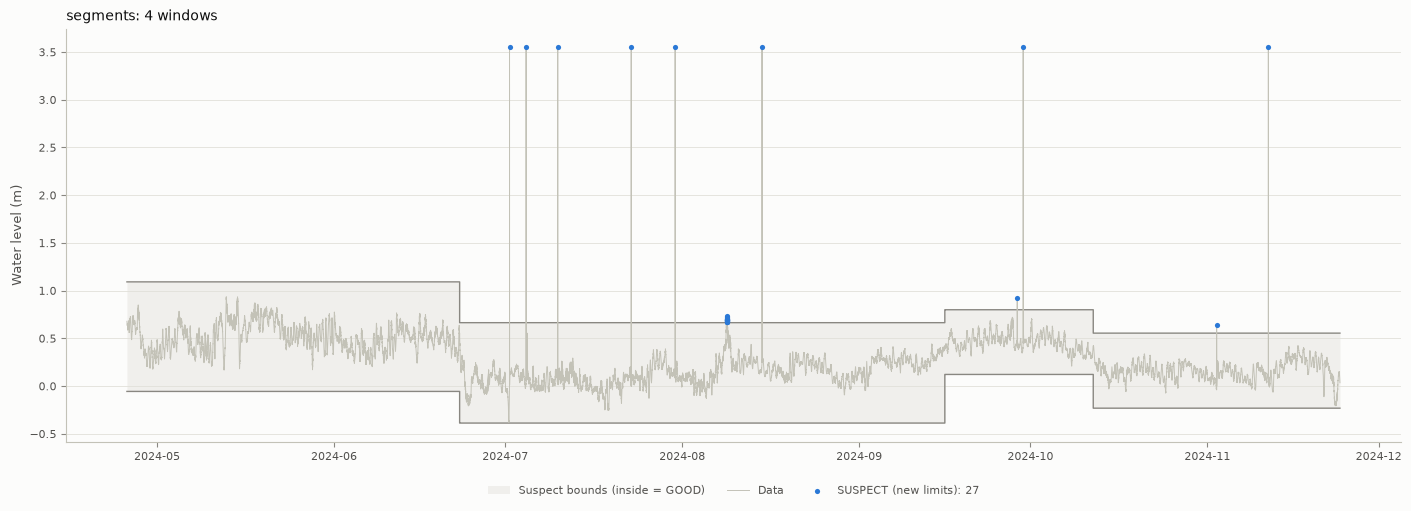

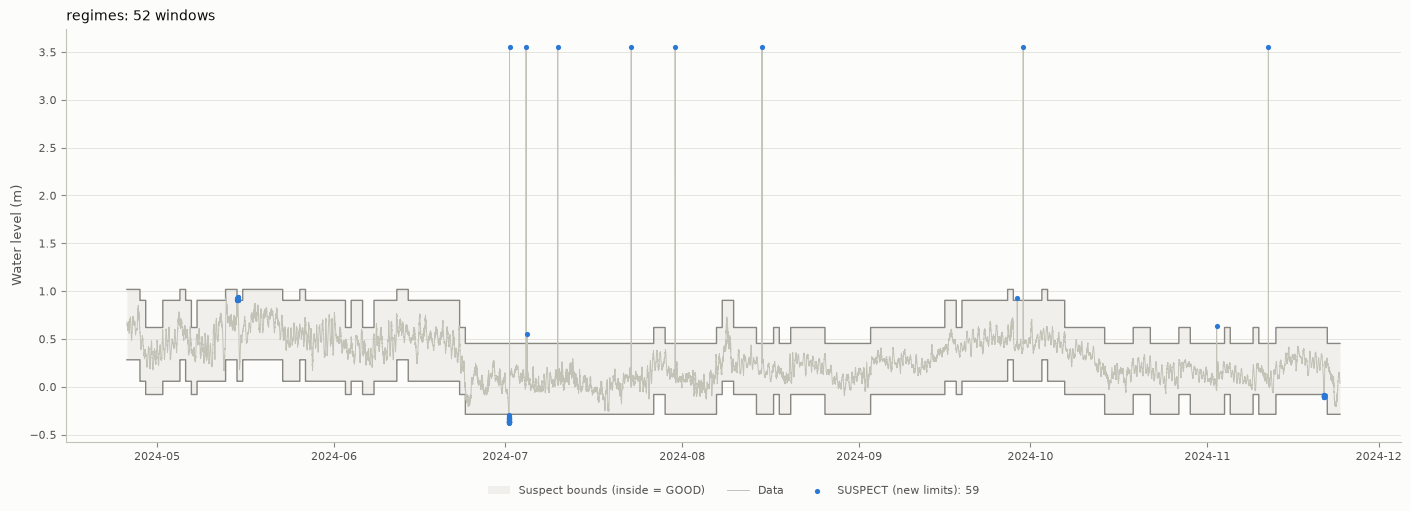

In [5]:
sub = slice(10000, 60000)  # 2024-04-25 to 2024-11-24
wl, wl2, t, ref = water_level[sub], water_level2[sub], time.iloc[sub], existing_qc[sub]

methods = {
    "seasonal (month)": dict(method="seasonal", period="month"),    #   As a reference, comparable to the previous cell
    "seasonal (weekofyear)": dict(method="seasonal", period="weekofyear"),
    "segments": dict(method="segments"),
    "regimes": dict(method="regimes"),
}

configs = {}
for name, kwargs in methods.items():
    cfg = auto_climatology(wl2, t, n_regimes=4, n_std=4, **kwargs)
    configs[name] = cfg
    plot_limits(wl, t, cfg, title=f"{name}: {len(cfg)} windows", ylabel="Water level (m)")
    print(f"{name}: {len(cfg)} windows")

* There are 8 months in the subsection for `seasonal` and `month`, but with 4 regimes, so it groups several months into other regimes that look like it. This is why there are 6 distinct windows, given 4 regimes, for 8 months of data.
* For the `seasonal` method with `weekofyear`, this is similar. Of the 31 weeks listed, bunch them into the regimes they're most familiar to. This caps at 4 regimes, so a total of 9 unique windows are seen.
* `Segments` makes sense - it's 4 segments for 4 regimes, so each gets its own window.
* Meanwhile specifying `regimes` will cluster each individual day and ID which of the 4 permitted regimes this day belongs to. If that day is followed by another day that also fits that regime, it clumps together and that's why there are 52 windows returned.

All of these runs create climatology configurations which can then be further modified or passed straight into a data pipeline.

##  Conclusion and recommendations
If you don't know what your limits should be, we recommend running the `auto_limits` module with the default settings. 

This means:
* `gross_range_test`
    * Suspect limits: Begin with 3 standard deviations. If it is flagging too much, increase the value of `n_std`.
    * Fail limits: Get the manufacturer specified measurement ranges if possible. Otherwise, consider making your fail limits the same way as your suspect limits with n_std of a larger value than the suspect limits.
* `climatology_test`
    * Run with the seasonal, monthly defaults and 3 standard deviations. If you need more potential ranges, increase the value of `n_regimes`. Increase the standard deviations if not enough data is being flagged.
* Plot your results with `plot_limits` and confirm that the bounds look reasonable for your use case.
* Tweak the limits iteratively from there and save them to your QARTOD flagging routine.

```python
#   Gross range
suspect = auto_thresh(var)
fail = (manufacturer_min, manufacturer_max)
flags = qartod.gross_range_test(var, fail_span=fail, suspect_span=suspect)
fig = plot_limits(var, time, limits=suspect, fail_span=fail)

#   Climatology
find_regimes(var, time)
cfg = auto_climatology(var, time)
flags = qartod.climatology_test(cfg, var, time)
fig = plot_limits(var, time, cfg)
```

Finding your limits is an iterative process and identifying them statistically is just a first step. Nothing beats a discussion with scientists, experienced field techs, or consulting scientific literature!